In [5]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [6]:
# Q1a) Normalisation
PIXEL_MAX = tf.reduce_max(x_train)

x_train = x_train / PIXEL_MAX
x_test = x_test / PIXEL_MAX

# Q1b) Reshape
TIME_STEPS = 28
FEATURES = 28

x_train = tf.reshape(x_train, (-1, TIME_STEPS, FEATURES))
x_test = tf.reshape(x_test, (-1, TIME_STEPS, FEATURES))

# Q1c) One-hot encoding
NUM_CLASSES = 10

y_train = to_categorical(y_train, NUM_CLASSES)
y_test = to_categorical(y_test, NUM_CLASSES)

print("prepared:", x_train.shape, y_train.shape)

prepared: (60000, 28, 28) (60000, 10)


In [7]:
from tensorflow.keras import models, layers

model = models.Sequential()

# Q2a) LSTM layer
LSTM_UNITS = 64

model.add(layers.LSTM(
    LSTM_UNITS,
    activation='tanh',
    input_shape=(28, 28)
))

# Q2b) Output layer
OUT_UNITS = 10

model.add(layers.Dense(
    OUT_UNITS,
    activation='softmax'
))

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        23,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,458 (95.54 KB)

 Trainable params: 24,458 (95.54 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# Q3a) Compile
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Q3b) Train
history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=32,
    validation_data=(x_test, y_test)
)

# Q3c) Evaluate
test_loss, test_acc = model.evaluate(x_test, y_test)

print(f"Test accuracy: {test_acc * 100:.2f}%")

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 28s 14ms/step - accuracy: 0.8639 - loss: 0.4306 - val_accuracy: 0.9570 - val_loss: 0.1404
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 42s 14ms/step - accuracy: 0.9611 - loss: 0.1320 - val_accuracy: 0.9725 - val_loss: 0.0920
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 26s 14ms/step - accuracy: 0.9710 - loss: 0.0952 - val_accuracy: 0.9755 - val_loss: 0.0771
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 26s 14ms/step - accuracy: 0.9778 - loss: 0.0720 - val_accuracy: 0.9798 - val_loss: 0.0683
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 26s 14ms/step - accuracy: 0.9810 - loss: 0.0622 - val_accuracy: 0.9810 - val_loss: 0.0626
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9810 - loss: 0.0626
Test accuracy: 98.10%


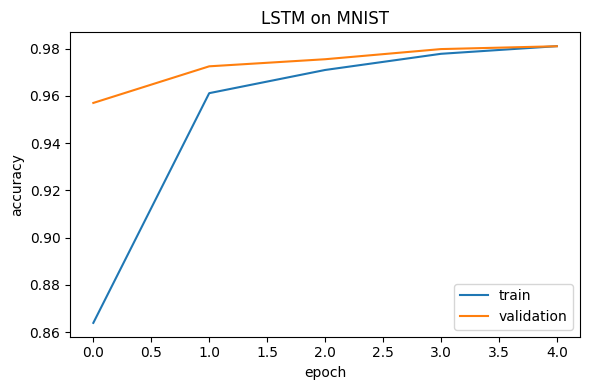

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))

plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='validation')

plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.legend()
plt.title('LSTM on MNIST')
plt.tight_layout()
plt.show()